# 03 — KPIs oficiais por período e por mês

**Objetivo:** calcular os três KPIs da proposta a partir das tabelas do notebook 02, preservando numeradores e denominadores, e comparar com os valores de referência (que ficam em colunas **separadas** dos valores calculados).

| KPI | Fórmula | Tabela-base |
|---|---|---|
| KPI1 — % avaliação ruim | pedidos com nota 1–2 / pedidos com avaliação válida × 100 | `pedidos` |
| KPI2 — % frete sobre produto | Σ `freight_value` / Σ `price` × 100 | `itens` |
| KPI3 — % postagem no prazo | pedidos postados até o menor `shipping_limit_date` / pedidos elegíveis × 100 | `pedidos` |

Rótulos: **2024 (proxy jan–ago/2017)** e **2025 (proxy jan–ago/2018)**: comparação acadêmica, não dados reais de 2024/2025.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import olist_utils as U

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid")

pedidos = U.load_processed("pedidos")
itens = U.load_processed("itens")
print(pedidos.shape, itens.shape)

(74781, 41) (85267, 26)


## 1. KPIs por período (resumo)

In [2]:
chave = ["ano_original", "periodo_comparativo"]
k_ped = U.kpi_pedidos(pedidos, chave)
k_fre = U.kpi_frete(itens, chave)
resumo = k_ped.merge(k_fre, on=chave, validate="one_to_one")

# Referências e metas da proposta em colunas separadas (não são valores calculados)
for kpi, refs in U.REFERENCIAS.items():
    resumo[f"{kpi}_referencia_proposta"] = resumo["ano_original"].map({2017: refs["ref_2024"], 2018: refs["ref_2025"]})
    resumo[f"{kpi}_diferenca_pp_vs_referencia"] = (resumo[kpi].round(1) - resumo[f"{kpi}_referencia_proposta"]).round(2)
    resumo[f"{kpi}_meta_2026"] = refs["meta_2026"]
    resumo[f"{kpi}_meta_2027"] = refs["meta_2027"]
resumo["pedidos_referencia_proposta"] = resumo["ano_original"].map(U.CHECK_PEDIDOS_PROPOSTA)
resumo["granularidade"] = "periodo"

cols_show = ["periodo_comparativo", "pedidos_entregues", "pedidos_com_avaliacao", "pedidos_avaliacao_ruim",
             "kpi1_pct_avaliacao_ruim", "soma_frete", "soma_preco_produtos", "kpi2_pct_frete_sobre_produto",
             "pedidos_postagem_elegiveis", "pedidos_postagem_no_prazo", "kpi3_pct_postagem_no_prazo",
             "pct_entrega_atrasada"]
resumo[cols_show].round(2).T

,0,1
periodo_comparativo,2024 (proxy jan-ago/2017),2025 (proxy jan-ago/2018)
pedidos_entregues,21998,52783
pedidos_com_avaliacao,21837,52468
pedidos_avaliacao_ruim,2312,7016
kpi1_pct_avaliacao_ruim,10.59,13.37
soma_frete,479442.12,1233459.65
soma_preco_produtos,2993456.13,7218125.12
kpi2_pct_frete_sobre_produto,16.02,17.09
pedidos_postagem_elegiveis,21997,52783
pedidos_postagem_no_prazo,20103,48271


### Comparação com os valores de referência da proposta

In [3]:
comp = []
for kpi in U.REFERENCIAS:
    for _, r in resumo.iterrows():
        comp.append({"kpi": kpi, "periodo": r["periodo_comparativo"], "calculado": round(r[kpi], 2),
                     "referencia_proposta": r[f"{kpi}_referencia_proposta"],
                     "dif_pp (arredondado 1 casa)": r[f"{kpi}_diferenca_pp_vs_referencia"],
                     "meta_2026": r[f"{kpi}_meta_2026"], "meta_2027": r[f"{kpi}_meta_2027"]})
comp = pd.DataFrame(comp)
comp

,kpi,periodo,calculado,referencia_proposta,dif_pp (arredondado 1 casa),meta_2026,meta_2027
0,kpi1_pct_avaliacao_ruim,2024 (proxy jan-ago/2017),10.59,10.6,0.0,12.0,10.0
1,kpi1_pct_avaliacao_ruim,2025 (proxy jan-ago/2018),13.37,13.4,0.0,12.0,10.0
2,kpi2_pct_frete_sobre_produto,2024 (proxy jan-ago/2017),16.02,16.0,0.0,17.1,17.1
3,kpi2_pct_frete_sobre_produto,2025 (proxy jan-ago/2018),17.09,17.1,0.0,17.1,17.1
4,kpi3_pct_postagem_no_prazo,2024 (proxy jan-ago/2017),91.39,91.4,0.0,95.0,97.0
5,kpi3_pct_postagem_no_prazo,2025 (proxy jan-ago/2018),91.45,91.5,0.0,95.0,97.0


In [4]:
# Variação entre os períodos (p.p.)
var = resumo.set_index("ano_original")[list(U.REFERENCIAS) + ["pct_entrega_atrasada"]]
(var.loc[2018] - var.loc[2017]).round(2).to_frame("variacao_pp_2025_vs_2024")

,variacao_pp_2025_vs_2024
kpi1_pct_avaliacao_ruim,2.78
kpi2_pct_frete_sobre_produto,1.07
kpi3_pct_postagem_no_prazo,0.06
pct_entrega_atrasada,4.23


## 2. KPIs por mês

In [5]:
chave_m = ["ano_original", "periodo_comparativo", "mes", "ano_mes_original"]
mensal = U.kpi_pedidos(pedidos, chave_m).merge(U.kpi_frete(itens, chave_m), on=chave_m, validate="one_to_one")
mensal["granularidade"] = "periodo_mes"
mensal[["ano_mes_original", "pedidos_entregues", "pedidos_com_avaliacao", "kpi1_pct_avaliacao_ruim",
        "kpi2_pct_frete_sobre_produto", "kpi3_pct_postagem_no_prazo", "pct_entrega_atrasada"]].round(2)

,ano_mes_original,pedidos_entregues,pedidos_com_avaliacao,kpi1_pct_avaliacao_ruim,kpi2_pct_frete_sobre_produto,kpi3_pct_postagem_no_prazo,pct_entrega_atrasada
0,2017-01,750,741,12.01,14.03,77.73,2.93
1,2017-02,1653,1643,11.08,15.80,82.46,2.96
2,2017-03,2546,2527,11.24,15.35,93.21,4.56
3,2017-04,2303,2290,12.88,14.72,92.71,6.56
4,2017-05,3546,3518,10.06,15.84,92.69,2.99
5,2017-06,3135,3111,10.74,16.15,92.03,3.03
6,2017-07,3872,3842,9.97,17.59,92.20,2.79
7,2017-08,4193,4165,9.39,16.43,93.20,2.91
8,2018-01,7069,7013,13.70,16.57,89.86,5.70
9,2018-02,6555,6507,19.38,16.91,87.77,14.13


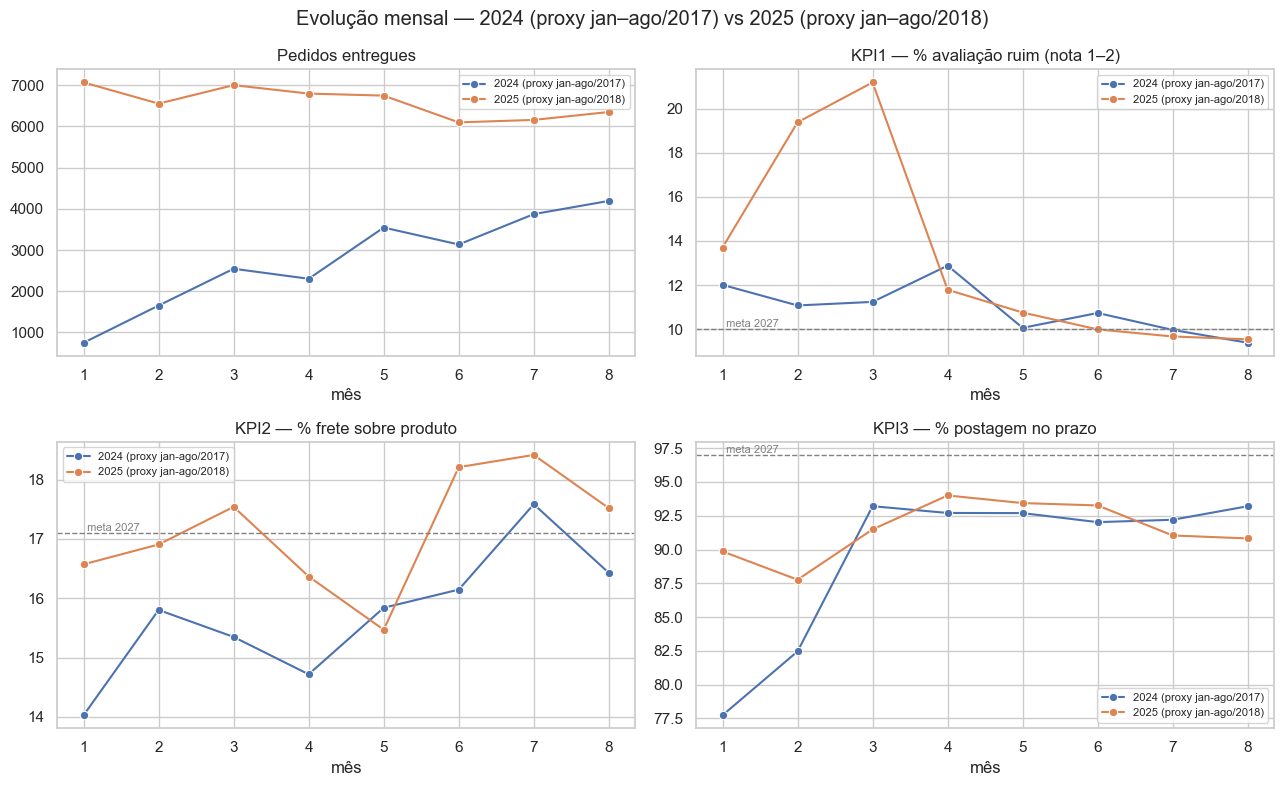

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, (col, titulo) in zip(axes.flat, [
        ("pedidos_entregues", "Pedidos entregues"),
        ("kpi1_pct_avaliacao_ruim", "KPI1 — % avaliação ruim (nota 1–2)"),
        ("kpi2_pct_frete_sobre_produto", "KPI2 — % frete sobre produto"),
        ("kpi3_pct_postagem_no_prazo", "KPI3 — % postagem no prazo")]):
    sns.lineplot(data=mensal, x="mes", y=col, hue="periodo_comparativo", marker="o", ax=ax)
    ax.set_title(titulo); ax.set_xlabel("mês"); ax.set_ylabel("")
    ax.legend(fontsize=8)
for ax, kpi in [(axes[0, 1], "kpi1_pct_avaliacao_ruim"), (axes[1, 0], "kpi2_pct_frete_sobre_produto"),
                (axes[1, 1], "kpi3_pct_postagem_no_prazo")]:
    ax.axhline(U.REFERENCIAS[kpi]["meta_2027"], ls="--", c="gray", lw=1)
    ax.text(1, U.REFERENCIAS[kpi]["meta_2027"], " meta 2027", va="bottom", fontsize=8, color="gray")
fig.suptitle("Evolução mensal — 2024 (proxy jan–ago/2017) vs 2025 (proxy jan–ago/2018)")
fig.tight_layout()
fig.savefig(U.FIG_DIR / "03_kpis_mensais.png", dpi=120)

## 3. Distribuição das notas e pedidos sem avaliação
O KPI1 olha a cauda (notas 1–2), não a média — a média aparece só como contexto.

periodo_comparativo,2024 (proxy jan-ago/2017),2025 (proxy jan-ago/2018)
review_score,,
1.0,7.62,10.36
2.0,2.97,3.01
3.0,8.53,8.04
4.0,20.29,19.27
5.0,60.60,59.32


,nota_media (apenas contexto)
periodo_comparativo,
2024 (proxy jan-ago/2017),4.233
2025 (proxy jan-ago/2018),4.142


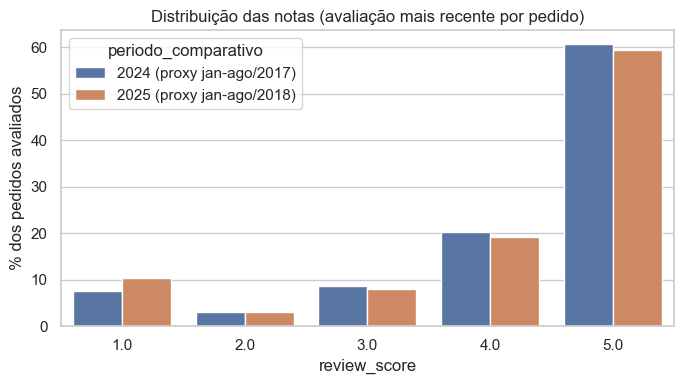

In [7]:
dist = (pedidos[pedidos["tem_avaliacao"]]
        .groupby(["periodo_comparativo", "review_score"]).size().rename("pedidos").reset_index())
dist["pct"] = dist["pedidos"] / dist.groupby("periodo_comparativo")["pedidos"].transform("sum") * 100
display(dist.pivot(index="review_score", columns="periodo_comparativo", values="pct").round(2))
display(pedidos.groupby("periodo_comparativo")["review_score"].mean().round(3).to_frame("nota_media (apenas contexto)"))

fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(data=dist, x="review_score", y="pct", hue="periodo_comparativo", ax=ax)
ax.set_title("Distribuição das notas (avaliação mais recente por pedido)"); ax.set_ylabel("% dos pedidos avaliados")
fig.tight_layout(); fig.savefig(U.FIG_DIR / "03_distribuicao_notas.png", dpi=120)

## 4. Atraso de entrega ao cliente
`dias_atraso_entrega` = dia da entrega − dia estimado (positivo = atraso).

,count,mean,std,min,10%,25%,50%,75%,90%,max
periodo_comparativo,,,,,,,,,,
2024 (proxy jan-ago/2017),21997.0,-13.8,10.2,-140.0,-23.0,-18.0,-14.0,-10.0,-6.0,181.0
2025 (proxy jan-ago/2018),52777.0,-11.4,10.2,-147.0,-22.0,-17.0,-12.0,-6.0,-1.0,188.0


,atrasados_count,atrasados_mean,atrasados_std,atrasados_min,atrasados_50%,atrasados_75%,atrasados_90%,atrasados_max
periodo_comparativo,,,,,,,,
2024 (proxy jan-ago/2017),769.0,14.7,26.7,1.0,7.0,14.0,28.0,181.0
2025 (proxy jan-ago/2018),4078.0,9.9,11.7,1.0,7.0,13.0,22.0,188.0


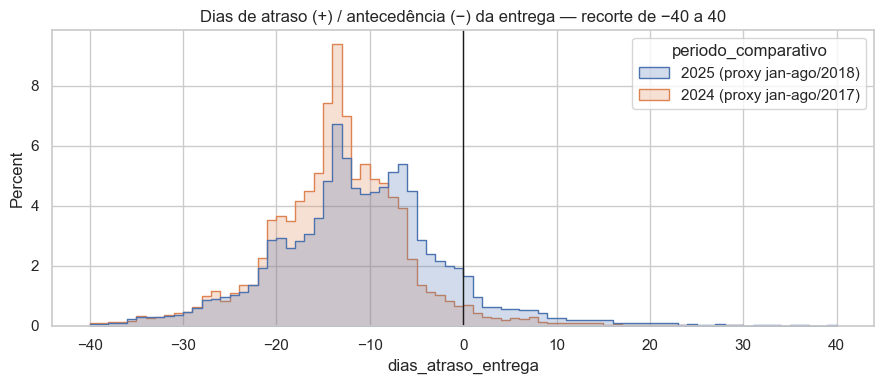

In [8]:
d = pedidos.dropna(subset=["dias_atraso_entrega"])
display(d.groupby("periodo_comparativo")["dias_atraso_entrega"].describe(percentiles=[.1, .25, .5, .75, .9]).round(1))
display(d[d["entrega_atrasada"] == True].groupby("periodo_comparativo")["dias_atraso_entrega"]
        .describe(percentiles=[.5, .75, .9]).round(1).rename(columns=lambda c: f"atrasados_{c}"))

fig, ax = plt.subplots(figsize=(9, 4))
sns.histplot(data=d[d["dias_atraso_entrega"].between(-40, 40)], x="dias_atraso_entrega",
             hue="periodo_comparativo", stat="percent", common_norm=False, binwidth=1, element="step", ax=ax)
ax.axvline(0, c="k", lw=1); ax.set_title("Dias de atraso (+) / antecedência (−) da entrega — recorte de −40 a 40")
fig.tight_layout(); fig.savefig(U.FIG_DIR / "03_dias_atraso_entrega.png", dpi=120)

## 5. Tempos do ciclo do pedido (mediana em dias)
Calculados apenas quando as duas datas existem; valores negativos (datas incoerentes) são mostrados à parte, não corrigidos.

In [9]:
tempos = ["dias_compra_aprovacao", "dias_aprovacao_postagem", "dias_postagem_entrega", "dias_compra_entrega"]
display(pedidos.groupby("periodo_comparativo")[tempos].median().round(2).T)
(pedidos[tempos] < 0).sum().to_frame("intervalos_negativos")

periodo_comparativo,2024 (proxy jan-ago/2017),2025 (proxy jan-ago/2018)
dias_compra_aprovacao,0.01,0.02
dias_aprovacao_postagem,1.84,1.60
dias_postagem_entrega,7.15,6.86
dias_compra_entrega,10.44,9.48


,intervalos_negativos
dias_compra_aprovacao,0
dias_aprovacao_postagem,1331
dias_postagem_entrega,19
dias_compra_entrega,0


## 6. Exportação

In [10]:
U.export_csv(resumo, "kpi_resumo_periodo")
U.export_csv(mensal, "kpi_mensal")
U.export_csv(dist.rename(columns={"pct": "pct_pedidos_avaliados"}), "distribuicao_notas")
print("Exportados: kpi_resumo_periodo.csv, kpi_mensal.csv, distribuicao_notas.csv")

Exportados: kpi_resumo_periodo.csv, kpi_mensal.csv, distribuicao_notas.csv


## Leitura dos resultados
Os números estão nas tabelas acima e são resumidos no README deste notebook e no relatório final. Os três KPIs calculados coincidem com os valores de referência da proposta quando arredondados para uma casa decimal, o que confirma que a definição usada aqui é a mesma do grupo.